# Wholesale Customers — compare three ways to segment customers

**Final applied lab · 60–75 minutes**

Which purchasing profiles should a distributor serve differently? Compare K-Means, hierarchical clustering and DBSCAN on the same six-dimensional representation. Use the introductory notebooks first. The business interpretation should follow the observed profiles.

Run cells in order in Jupyter or Colab. All data are embedded. If dependencies are missing, uncomment the installation command. Predict each result before running the next step.

In [1]:
# %pip install numpy pandas matplotlib scipy scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, silhouette_score
plt.rcParams.update({'figure.figsize': (7, 5), 'font.size': 11})


## 1. Load the real data
The dataset has 440 wholesale customers and six annual spending categories, expressed in monetary units. `Channel` and `Region` are reserved for interpretation after fitting.

| Input | Category |
|---|---|
| Fresh | Fresh products |
| Milk | Milk products |
| Grocery | Grocery products |
| Frozen | Frozen products |
| Detergents_Paper | Detergents and paper |
| Delicassen | Delicatessen products |

Source and attribution — Cardoso, M. (2013), *Wholesale customers*, UCI Machine Learning Repository, DOI 10.24432/C5030X, CC BY 4.0. [Dataset documentation](https://archive.ics.uci.edu/dataset/292/wholesale+customers). Original values are embedded below.

In [3]:
import io
CSV_DATA = 'Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen\n2,3,12669,9656,7561,214,2674,1338\n2,3,7057,9810,9568,1762,3293,1776\n2,3,6353,8808,7684,2405,3516,7844\n1,3,13265,1196,4221,6404,507,1788\n2,3,22615,5410,7198,3915,1777,5185\n2,3,9413,8259,5126,666,1795,1451\n2,3,12126,3199,6975,480,3140,545\n2,3,7579,4956,9426,1669,3321,2566\n1,3,5963,3648,6192,425,1716,750\n2,3,6006,11093,18881,1159,7425,2098\n2,3,3366,5403,12974,4400,5977,1744\n2,3,13146,1124,4523,1420,549,497\n2,3,31714,12319,11757,287,3881,2931\n2,3,21217,6208,14982,3095,6707,602\n2,3,24653,9465,12091,294,5058,2168\n1,3,10253,1114,3821,397,964,412\n2,3,1020,8816,12121,134,4508,1080\n1,3,5876,6157,2933,839,370,4478\n2,3,18601,6327,10099,2205,2767,3181\n1,3,7780,2495,9464,669,2518,501\n2,3,17546,4519,4602,1066,2259,2124\n1,3,5567,871,2010,3383,375,569\n1,3,31276,1917,4469,9408,2381,4334\n2,3,26373,36423,22019,5154,4337,16523\n2,3,22647,9776,13792,2915,4482,5778\n2,3,16165,4230,7595,201,4003,57\n1,3,9898,961,2861,3151,242,833\n1,3,14276,803,3045,485,100,518\n2,3,4113,20484,25957,1158,8604,5206\n1,3,43088,2100,2609,1200,1107,823\n1,3,18815,3610,11107,1148,2134,2963\n1,3,2612,4339,3133,2088,820,985\n1,3,21632,1318,2886,266,918,405\n1,3,29729,4786,7326,6130,361,1083\n1,3,1502,1979,2262,425,483,395\n2,3,688,5491,11091,833,4239,436\n1,3,29955,4362,5428,1729,862,4626\n2,3,15168,10556,12477,1920,6506,714\n2,3,4591,15729,16709,33,6956,433\n1,3,56159,555,902,10002,212,2916\n1,3,24025,4332,4757,9510,1145,5864\n1,3,19176,3065,5956,2033,2575,2802\n2,3,10850,7555,14961,188,6899,46\n2,3,630,11095,23998,787,9529,72\n2,3,9670,7027,10471,541,4618,65\n2,3,5181,22044,21531,1740,7353,4985\n2,3,3103,14069,21955,1668,6792,1452\n2,3,44466,54259,55571,7782,24171,6465\n2,3,11519,6152,10868,584,5121,1476\n2,3,4967,21412,28921,1798,13583,1163\n1,3,6269,1095,1980,3860,609,2162\n1,3,3347,4051,6996,239,1538,301\n2,3,40721,3916,5876,532,2587,1278\n2,3,491,10473,11532,744,5611,224\n1,3,27329,1449,1947,2436,204,1333\n1,3,5264,3683,5005,1057,2024,1130\n2,3,4098,29892,26866,2616,17740,1340\n2,3,5417,9933,10487,38,7572,1282\n1,3,13779,1970,1648,596,227,436\n1,3,6137,5360,8040,129,3084,1603\n2,3,8590,3045,7854,96,4095,225\n2,3,35942,38369,59598,3254,26701,2017\n2,3,7823,6245,6544,4154,4074,964\n2,3,9396,11601,15775,2896,7677,1295\n1,3,4760,1227,3250,3724,1247,1145\n2,3,85,20959,45828,36,24231,1423\n1,3,9,1534,7417,175,3468,27\n2,3,19913,6759,13462,1256,5141,834\n1,3,2446,7260,3993,5870,788,3095\n1,3,8352,2820,1293,779,656,144\n1,3,16705,2037,3202,10643,116,1365\n1,3,18291,1266,21042,5373,4173,14472\n1,3,4420,5139,2661,8872,1321,181\n2,3,19899,5332,8713,8132,764,648\n2,3,8190,6343,9794,1285,1901,1780\n1,3,20398,1137,3,4407,3,975\n1,3,717,3587,6532,7530,529,894\n2,3,12205,12697,28540,869,12034,1009\n1,3,10766,1175,2067,2096,301,167\n1,3,1640,3259,3655,868,1202,1653\n1,3,7005,829,3009,430,610,529\n2,3,219,9540,14403,283,7818,156\n2,3,10362,9232,11009,737,3537,2342\n1,3,20874,1563,1783,2320,550,772\n2,3,11867,3327,4814,1178,3837,120\n2,3,16117,46197,92780,1026,40827,2944\n2,3,22925,73498,32114,987,20070,903\n1,3,43265,5025,8117,6312,1579,14351\n1,3,7864,542,4042,9735,165,46\n1,3,24904,3836,5330,3443,454,3178\n1,3,11405,596,1638,3347,69,360\n1,3,12754,2762,2530,8693,627,1117\n2,3,9198,27472,32034,3232,18906,5130\n1,3,11314,3090,2062,35009,71,2698\n2,3,5626,12220,11323,206,5038,244\n1,3,3,2920,6252,440,223,709\n2,3,23,2616,8118,145,3874,217\n1,3,403,254,610,774,54,63\n1,3,503,112,778,895,56,132\n1,3,9658,2182,1909,5639,215,323\n2,3,11594,7779,12144,3252,8035,3029\n2,3,1420,10810,16267,1593,6766,1838\n2,3,2932,6459,7677,2561,4573,1386\n1,3,56082,3504,8906,18028,1480,2498\n1,3,14100,2132,3445,1336,1491,548\n1,3,15587,1014,3970,910,139,1378\n2,3,1454,6337,10704,133,6830,1831\n2,3,8797,10646,14886,2471,8969,1438\n2,3,1531,8397,6981,247,2505,1236\n2,3,1406,16729,28986,673,836,3\n1,3,11818,1648,1694,2276,169,1647\n2,3,12579,11114,17569,805,6457,1519\n1,3,19046,2770,2469,8853,483,2708\n1,3,14438,2295,1733,3220,585,1561\n1,3,18044,1080,2000,2555,118,1266\n1,3,11134,793,2988,2715,276,610\n1,3,11173,2521,3355,1517,310,222\n1,3,6990,3880,5380,1647,319,1160\n1,3,20049,1891,2362,5343,411,933\n1,3,8258,2344,2147,3896,266,635\n1,3,17160,1200,3412,2417,174,1136\n1,3,4020,3234,1498,2395,264,255\n1,3,12212,201,245,1991,25,860\n2,3,11170,10769,8814,2194,1976,143\n1,3,36050,1642,2961,4787,500,1621\n1,3,76237,3473,7102,16538,778,918\n1,3,19219,1840,1658,8195,349,483\n2,3,21465,7243,10685,880,2386,2749\n1,3,140,8847,3823,142,1062,3\n1,3,42312,926,1510,1718,410,1819\n1,3,7149,2428,699,6316,395,911\n1,3,2101,589,314,346,70,310\n1,3,14903,2032,2479,576,955,328\n1,3,9434,1042,1235,436,256,396\n1,3,7388,1882,2174,720,47,537\n1,3,6300,1289,2591,1170,199,326\n1,3,4625,8579,7030,4575,2447,1542\n1,3,3087,8080,8282,661,721,36\n1,3,13537,4257,5034,155,249,3271\n1,3,5387,4979,3343,825,637,929\n1,3,17623,4280,7305,2279,960,2616\n1,3,30379,13252,5189,321,51,1450\n1,3,37036,7152,8253,2995,20,3\n1,3,10405,1596,1096,8425,399,318\n1,3,18827,3677,1988,118,516,201\n2,3,22039,8384,34792,42,12591,4430\n1,3,7769,1936,2177,926,73,520\n1,3,9203,3373,2707,1286,1082,526\n1,3,5924,584,542,4052,283,434\n1,3,31812,1433,1651,800,113,1440\n1,3,16225,1825,1765,853,170,1067\n1,3,1289,3328,2022,531,255,1774\n1,3,18840,1371,3135,3001,352,184\n1,3,3463,9250,2368,779,302,1627\n1,3,622,55,137,75,7,8\n2,3,1989,10690,19460,233,11577,2153\n2,3,3830,5291,14855,317,6694,3182\n1,3,17773,1366,2474,3378,811,418\n2,3,2861,6570,9618,930,4004,1682\n2,3,355,7704,14682,398,8077,303\n2,3,1725,3651,12822,824,4424,2157\n1,3,12434,540,283,1092,3,2233\n1,3,15177,2024,3810,2665,232,610\n2,3,5531,15726,26870,2367,13726,446\n2,3,5224,7603,8584,2540,3674,238\n2,3,15615,12653,19858,4425,7108,2379\n2,3,4822,6721,9170,993,4973,3637\n1,3,2926,3195,3268,405,1680,693\n1,3,5809,735,803,1393,79,429\n1,3,5414,717,2155,2399,69,750\n2,3,260,8675,13430,1116,7015,323\n2,3,200,25862,19816,651,8773,6250\n1,3,955,5479,6536,333,2840,707\n2,3,514,7677,19805,937,9836,716\n1,3,286,1208,5241,2515,153,1442\n2,3,2343,7845,11874,52,4196,1697\n1,3,45640,6958,6536,7368,1532,230\n1,3,12759,7330,4533,1752,20,2631\n1,3,11002,7075,4945,1152,120,395\n1,3,3157,4888,2500,4477,273,2165\n1,3,12356,6036,8887,402,1382,2794\n1,3,112151,29627,18148,16745,4948,8550\n1,3,694,8533,10518,443,6907,156\n1,3,36847,43950,20170,36534,239,47943\n1,3,327,918,4710,74,334,11\n1,3,8170,6448,1139,2181,58,247\n1,3,3009,521,854,3470,949,727\n1,3,2438,8002,9819,6269,3459,3\n2,3,8040,7639,11687,2758,6839,404\n2,3,834,11577,11522,275,4027,1856\n1,3,16936,6250,1981,7332,118,64\n1,3,13624,295,1381,890,43,84\n1,3,5509,1461,2251,547,187,409\n2,3,180,3485,20292,959,5618,666\n1,3,7107,1012,2974,806,355,1142\n1,3,17023,5139,5230,7888,330,1755\n1,1,30624,7209,4897,18711,763,2876\n2,1,2427,7097,10391,1127,4314,1468\n1,1,11686,2154,6824,3527,592,697\n1,1,9670,2280,2112,520,402,347\n2,1,3067,13240,23127,3941,9959,731\n2,1,4484,14399,24708,3549,14235,1681\n1,1,25203,11487,9490,5065,284,6854\n1,1,583,685,2216,469,954,18\n1,1,1956,891,5226,1383,5,1328\n2,1,1107,11711,23596,955,9265,710\n1,1,6373,780,950,878,288,285\n2,1,2541,4737,6089,2946,5316,120\n1,1,1537,3748,5838,1859,3381,806\n2,1,5550,12729,16767,864,12420,797\n1,1,18567,1895,1393,1801,244,2100\n2,1,12119,28326,39694,4736,19410,2870\n1,1,7291,1012,2062,1291,240,1775\n1,1,3317,6602,6861,1329,3961,1215\n2,1,2362,6551,11364,913,5957,791\n1,1,2806,10765,15538,1374,5828,2388\n2,1,2532,16599,36486,179,13308,674\n1,1,18044,1475,2046,2532,130,1158\n2,1,18,7504,15205,1285,4797,6372\n1,1,4155,367,1390,2306,86,130\n1,1,14755,899,1382,1765,56,749\n1,1,5396,7503,10646,91,4167,239\n1,1,5041,1115,2856,7496,256,375\n2,1,2790,2527,5265,5612,788,1360\n1,1,7274,659,1499,784,70,659\n1,1,12680,3243,4157,660,761,786\n2,1,20782,5921,9212,1759,2568,1553\n1,1,4042,2204,1563,2286,263,689\n1,1,1869,577,572,950,4762,203\n1,1,8656,2746,2501,6845,694,980\n2,1,11072,5989,5615,8321,955,2137\n1,1,2344,10678,3828,1439,1566,490\n1,1,25962,1780,3838,638,284,834\n1,1,964,4984,3316,937,409,7\n1,1,15603,2703,3833,4260,325,2563\n1,1,1838,6380,2824,1218,1216,295\n1,1,8635,820,3047,2312,415,225\n1,1,18692,3838,593,4634,28,1215\n1,1,7363,475,585,1112,72,216\n1,1,47493,2567,3779,5243,828,2253\n1,1,22096,3575,7041,11422,343,2564\n1,1,24929,1801,2475,2216,412,1047\n1,1,18226,659,2914,3752,586,578\n1,1,11210,3576,5119,561,1682,2398\n1,1,6202,7775,10817,1183,3143,1970\n2,1,3062,6154,13916,230,8933,2784\n1,1,8885,2428,1777,1777,430,610\n1,1,13569,346,489,2077,44,659\n1,1,15671,5279,2406,559,562,572\n1,1,8040,3795,2070,6340,918,291\n1,1,3191,1993,1799,1730,234,710\n2,1,6134,23133,33586,6746,18594,5121\n1,1,6623,1860,4740,7683,205,1693\n1,1,29526,7961,16966,432,363,1391\n1,1,10379,17972,4748,4686,1547,3265\n1,1,31614,489,1495,3242,111,615\n1,1,11092,5008,5249,453,392,373\n1,1,8475,1931,1883,5004,3593,987\n1,1,56083,4563,2124,6422,730,3321\n1,1,53205,4959,7336,3012,967,818\n1,1,9193,4885,2157,327,780,548\n1,1,7858,1110,1094,6818,49,287\n1,1,23257,1372,1677,982,429,655\n1,1,2153,1115,6684,4324,2894,411\n2,1,1073,9679,15445,61,5980,1265\n1,1,5909,23527,13699,10155,830,3636\n2,1,572,9763,22182,2221,4882,2563\n1,1,20893,1222,2576,3975,737,3628\n2,1,11908,8053,19847,1069,6374,698\n1,1,15218,258,1138,2516,333,204\n1,1,4720,1032,975,5500,197,56\n1,1,2083,5007,1563,1120,147,1550\n1,1,514,8323,6869,529,93,1040\n1,3,36817,3045,1493,4802,210,1824\n1,3,894,1703,1841,744,759,1153\n1,3,680,1610,223,862,96,379\n1,3,27901,3749,6964,4479,603,2503\n1,3,9061,829,683,16919,621,139\n1,3,11693,2317,2543,5845,274,1409\n2,3,17360,6200,9694,1293,3620,1721\n1,3,3366,2884,2431,977,167,1104\n2,3,12238,7108,6235,1093,2328,2079\n1,3,49063,3965,4252,5970,1041,1404\n1,3,25767,3613,2013,10303,314,1384\n1,3,68951,4411,12609,8692,751,2406\n1,3,40254,640,3600,1042,436,18\n1,3,7149,2247,1242,1619,1226,128\n1,3,15354,2102,2828,8366,386,1027\n1,3,16260,594,1296,848,445,258\n1,3,42786,286,471,1388,32,22\n1,3,2708,2160,2642,502,965,1522\n1,3,6022,3354,3261,2507,212,686\n1,3,2838,3086,4329,3838,825,1060\n2,2,3996,11103,12469,902,5952,741\n1,2,21273,2013,6550,909,811,1854\n2,2,7588,1897,5234,417,2208,254\n1,2,19087,1304,3643,3045,710,898\n2,2,8090,3199,6986,1455,3712,531\n2,2,6758,4560,9965,934,4538,1037\n1,2,444,879,2060,264,290,259\n2,2,16448,6243,6360,824,2662,2005\n2,2,5283,13316,20399,1809,8752,172\n2,2,2886,5302,9785,364,6236,555\n2,2,2599,3688,13829,492,10069,59\n2,2,161,7460,24773,617,11783,2410\n2,2,243,12939,8852,799,3909,211\n2,2,6468,12867,21570,1840,7558,1543\n1,2,17327,2374,2842,1149,351,925\n1,2,6987,1020,3007,416,257,656\n2,2,918,20655,13567,1465,6846,806\n1,2,7034,1492,2405,12569,299,1117\n1,2,29635,2335,8280,3046,371,117\n2,2,2137,3737,19172,1274,17120,142\n1,2,9784,925,2405,4447,183,297\n1,2,10617,1795,7647,1483,857,1233\n2,2,1479,14982,11924,662,3891,3508\n1,2,7127,1375,2201,2679,83,1059\n1,2,1182,3088,6114,978,821,1637\n1,2,11800,2713,3558,2121,706,51\n2,2,9759,25071,17645,1128,12408,1625\n1,2,1774,3696,2280,514,275,834\n1,2,9155,1897,5167,2714,228,1113\n1,2,15881,713,3315,3703,1470,229\n1,2,13360,944,11593,915,1679,573\n1,2,25977,3587,2464,2369,140,1092\n1,2,32717,16784,13626,60869,1272,5609\n1,2,4414,1610,1431,3498,387,834\n1,2,542,899,1664,414,88,522\n1,2,16933,2209,3389,7849,210,1534\n1,2,5113,1486,4583,5127,492,739\n1,2,9790,1786,5109,3570,182,1043\n2,2,11223,14881,26839,1234,9606,1102\n1,2,22321,3216,1447,2208,178,2602\n2,2,8565,4980,67298,131,38102,1215\n2,2,16823,928,2743,11559,332,3486\n2,2,27082,6817,10790,1365,4111,2139\n1,2,13970,1511,1330,650,146,778\n1,2,9351,1347,2611,8170,442,868\n1,2,3,333,7021,15601,15,550\n1,2,2617,1188,5332,9584,573,1942\n2,3,381,4025,9670,388,7271,1371\n2,3,2320,5763,11238,767,5162,2158\n1,3,255,5758,5923,349,4595,1328\n2,3,1689,6964,26316,1456,15469,37\n1,3,3043,1172,1763,2234,217,379\n1,3,1198,2602,8335,402,3843,303\n2,3,2771,6939,15541,2693,6600,1115\n2,3,27380,7184,12311,2809,4621,1022\n1,3,3428,2380,2028,1341,1184,665\n2,3,5981,14641,20521,2005,12218,445\n1,3,3521,1099,1997,1796,173,995\n2,3,1210,10044,22294,1741,12638,3137\n1,3,608,1106,1533,830,90,195\n2,3,117,6264,21203,228,8682,1111\n1,3,14039,7393,2548,6386,1333,2341\n1,3,190,727,2012,245,184,127\n1,3,22686,134,218,3157,9,548\n2,3,37,1275,22272,137,6747,110\n1,3,759,18664,1660,6114,536,4100\n1,3,796,5878,2109,340,232,776\n1,3,19746,2872,2006,2601,468,503\n1,3,4734,607,864,1206,159,405\n1,3,2121,1601,2453,560,179,712\n1,3,4627,997,4438,191,1335,314\n1,3,2615,873,1524,1103,514,468\n2,3,4692,6128,8025,1619,4515,3105\n1,3,9561,2217,1664,1173,222,447\n1,3,3477,894,534,1457,252,342\n1,3,22335,1196,2406,2046,101,558\n1,3,6211,337,683,1089,41,296\n2,3,39679,3944,4955,1364,523,2235\n1,3,20105,1887,1939,8164,716,790\n1,3,3884,3801,1641,876,397,4829\n2,3,15076,6257,7398,1504,1916,3113\n1,3,6338,2256,1668,1492,311,686\n1,3,5841,1450,1162,597,476,70\n2,3,3136,8630,13586,5641,4666,1426\n1,3,38793,3154,2648,1034,96,1242\n1,3,3225,3294,1902,282,68,1114\n2,3,4048,5164,10391,130,813,179\n1,3,28257,944,2146,3881,600,270\n1,3,17770,4591,1617,9927,246,532\n1,3,34454,7435,8469,2540,1711,2893\n1,3,1821,1364,3450,4006,397,361\n1,3,10683,21858,15400,3635,282,5120\n1,3,11635,922,1614,2583,192,1068\n1,3,1206,3620,2857,1945,353,967\n1,3,20918,1916,1573,1960,231,961\n1,3,9785,848,1172,1677,200,406\n1,3,9385,1530,1422,3019,227,684\n1,3,3352,1181,1328,5502,311,1000\n1,3,2647,2761,2313,907,95,1827\n1,3,518,4180,3600,659,122,654\n1,3,23632,6730,3842,8620,385,819\n1,3,12377,865,3204,1398,149,452\n1,3,9602,1316,1263,2921,841,290\n2,3,4515,11991,9345,2644,3378,2213\n1,3,11535,1666,1428,6838,64,743\n1,3,11442,1032,582,5390,74,247\n1,3,9612,577,935,1601,469,375\n1,3,4446,906,1238,3576,153,1014\n1,3,27167,2801,2128,13223,92,1902\n1,3,26539,4753,5091,220,10,340\n1,3,25606,11006,4604,127,632,288\n1,3,18073,4613,3444,4324,914,715\n1,3,6884,1046,1167,2069,593,378\n1,3,25066,5010,5026,9806,1092,960\n2,3,7362,12844,18683,2854,7883,553\n2,3,8257,3880,6407,1646,2730,344\n1,3,8708,3634,6100,2349,2123,5137\n1,3,6633,2096,4563,1389,1860,1892\n1,3,2126,3289,3281,1535,235,4365\n1,3,97,3605,12400,98,2970,62\n1,3,4983,4859,6633,17866,912,2435\n1,3,5969,1990,3417,5679,1135,290\n2,3,7842,6046,8552,1691,3540,1874\n2,3,4389,10940,10908,848,6728,993\n1,3,5065,5499,11055,364,3485,1063\n2,3,660,8494,18622,133,6740,776\n1,3,8861,3783,2223,633,1580,1521\n1,3,4456,5266,13227,25,6818,1393\n2,3,17063,4847,9053,1031,3415,1784\n1,3,26400,1377,4172,830,948,1218\n2,3,17565,3686,4657,1059,1803,668\n2,3,16980,2884,12232,874,3213,249\n1,3,11243,2408,2593,15348,108,1886\n1,3,13134,9347,14316,3141,5079,1894\n1,3,31012,16687,5429,15082,439,1163\n1,3,3047,5970,4910,2198,850,317\n1,3,8607,1750,3580,47,84,2501\n1,3,3097,4230,16483,575,241,2080\n1,3,8533,5506,5160,13486,1377,1498\n1,3,21117,1162,4754,269,1328,395\n1,3,1982,3218,1493,1541,356,1449\n1,3,16731,3922,7994,688,2371,838\n1,3,29703,12051,16027,13135,182,2204\n1,3,39228,1431,764,4510,93,2346\n2,3,14531,15488,30243,437,14841,1867\n1,3,10290,1981,2232,1038,168,2125\n1,3,2787,1698,2510,65,477,52\n'
data = pd.read_csv(io.StringIO(CSV_DATA))
features = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
X = data[features].astype(float)
assert X.shape == (440,6)
assert not X.isna().any().any()
assert (X>=0).all().all()
display(data.head())
display(X.describe().round(1))

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.3,5796.3,7951.3,3071.9,2881.5,1524.9
std,12647.3,7380.4,9503.2,4854.7,4767.9,2820.1
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3127.8,1533.0,2153.0,742.2,256.8,408.2
50%,8504.0,3627.0,4755.5,1526.0,816.5,965.5
75%,16933.8,7190.2,10655.8,3554.2,3922.0,1820.2
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


## 2. Choose what similarity means
Large spenders and long right tails can dominate Euclidean distances. We use
$$u_{ij}=\log(1+x_{ij}),\qquad z_{ij}=\frac{u_{ij}-\mu_j}{s_j}.$$
The log transformation compresses large absolute differences. Standardization gives each transformed category equal initial variance. This emphasizes relative spending patterns while retaining some overall purchasing-volume information.

These choices affect the segments. Compare the histograms before accepting them.

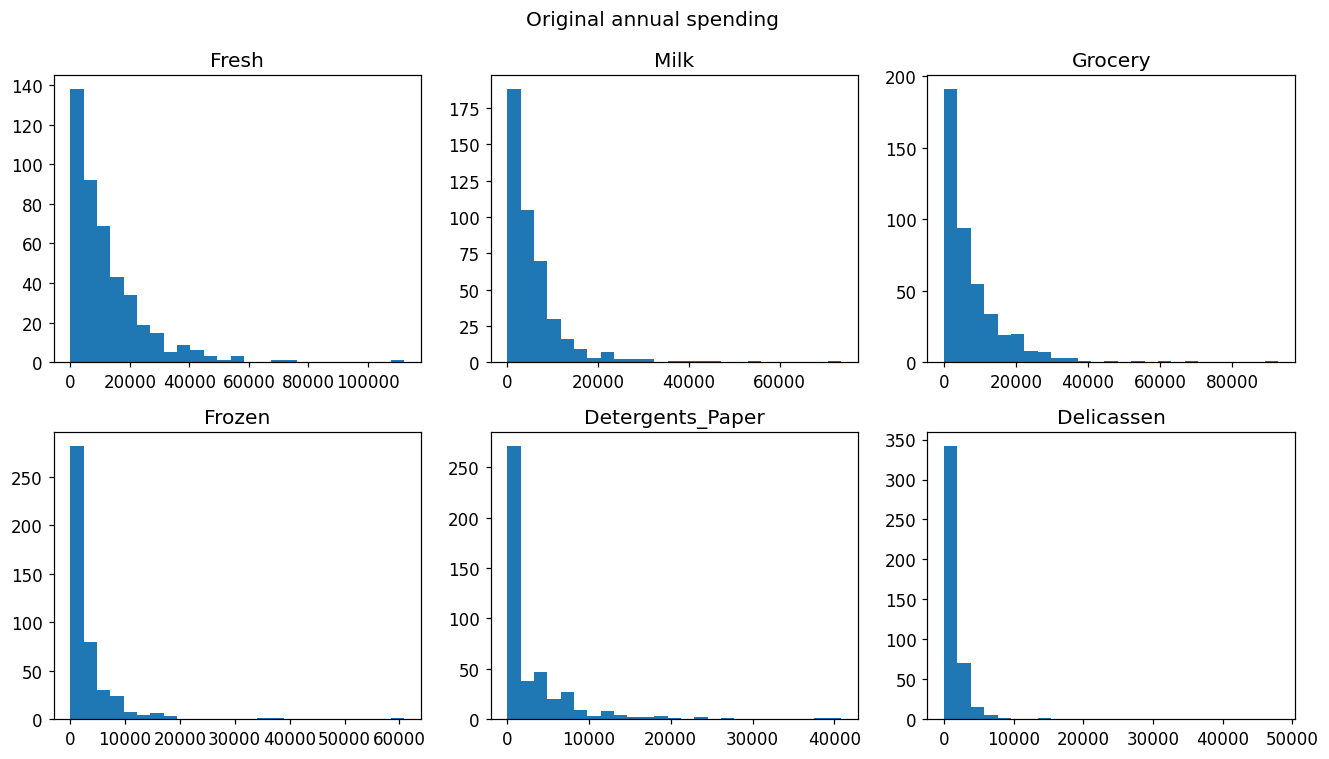

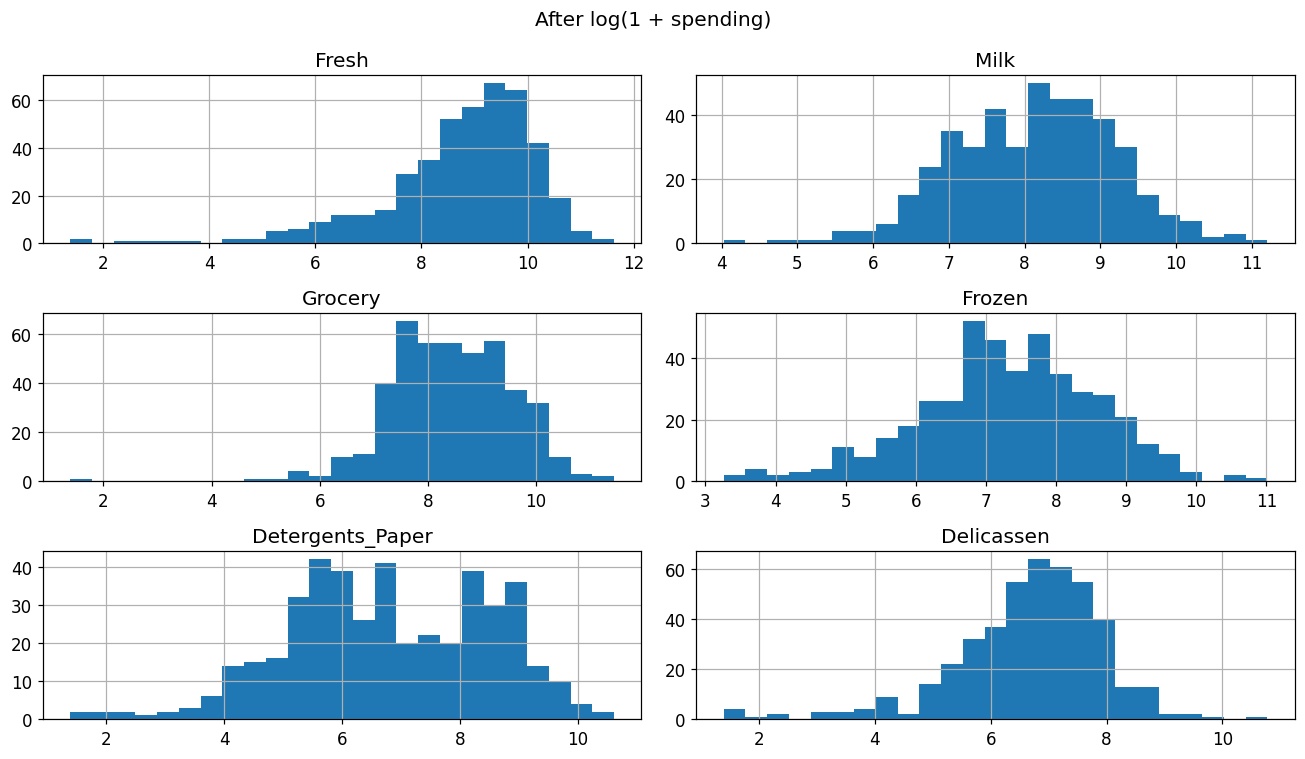

In [4]:
from sklearn.preprocessing import StandardScaler
logged = np.log1p(X)
scaler = StandardScaler()
Z = scaler.fit_transform(logged)
fig,axes = plt.subplots(2,3,figsize=(12,7))
for column,ax in zip(features,axes.flat):
    ax.hist(X[column],bins=25); ax.set_title(column)
fig.suptitle('Original annual spending'); plt.tight_layout(); plt.show()
logged.hist(figsize=(12,7),bins=25)
plt.suptitle('After log(1 + spending)'); plt.tight_layout(); plt.show()
assert np.allclose(Z.mean(axis=0),0)
assert np.allclose(Z.var(axis=0),1)


## 3. Examine candidate group counts
We compare inertia and silhouette for K-Means, and silhouette for Ward hierarchical clustering. Silhouette compares within-group cohesion with separation from other groups. Higher values favor separation under the chosen distance. Interpret it together with segment size and business meaning.

,k,Inertia,KMeans silhouette,Ward silhouette
0,2,1844.064,0.290,0.258
1,3,1553.413,0.258,0.255
2,4,1386.863,0.188,0.202
3,5,1266.149,0.192,0.203
4,6,1174.536,0.195,0.171
5,7,1086.359,0.196,0.163


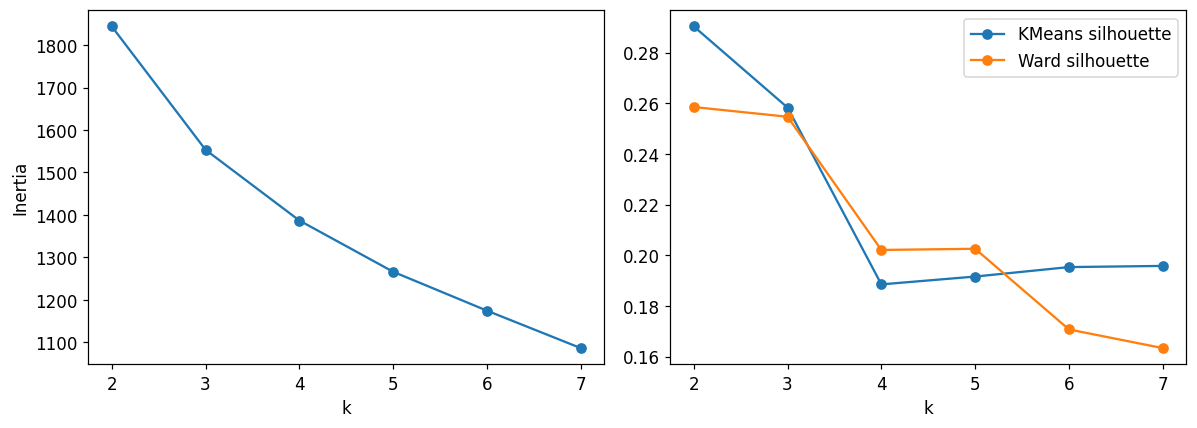

In [5]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
scores = []
for k in range(2,8):
    km = KMeans(n_clusters=k,n_init=20,random_state=42).fit(Z)
    ward = AgglomerativeClustering(n_clusters=k,linkage='ward').fit_predict(Z)
    scores.append([k,km.inertia_,silhouette_score(Z,km.labels_),silhouette_score(Z,ward)])
scores = pd.DataFrame(scores,columns=['k','Inertia','KMeans silhouette','Ward silhouette'])
display(scores.round(3))
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(scores['k'],scores['Inertia'],'o-'); axes[0].set(xlabel='k',ylabel='Inertia')
for column in ['KMeans silhouette','Ward silhouette']:
    axes[1].plot(scores['k'],scores[column],'o-',label=column)
axes[1].set_xlabel('k'); axes[1].legend(); plt.tight_layout(); plt.show()


## 4. Inspect the hierarchy
Ward merges groups to minimize the increase in within-group squared error. The dendrogram below is truncated to the last 20 groups for readability. Parenthesized leaf labels represent counts of observations. Compare several horizontal cuts mentally before choosing a group count.

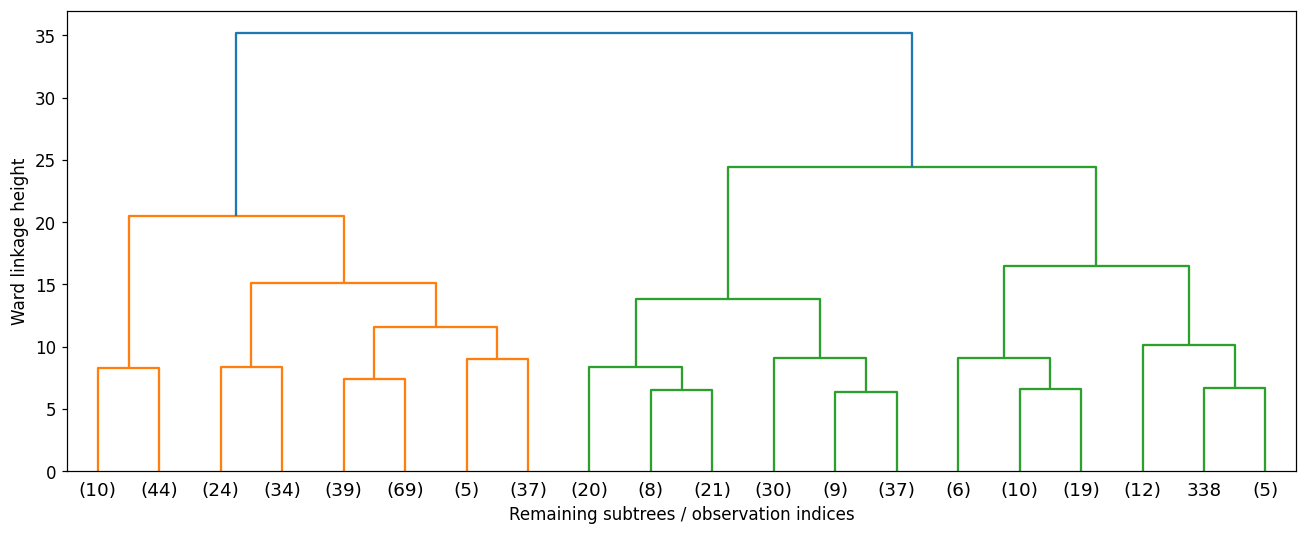

In [6]:
from scipy.cluster.hierarchy import linkage, dendrogram
ward_tree = linkage(Z,method='ward')
fig,ax=plt.subplots(figsize=(12,5))
dendrogram(ward_tree,truncate_mode='lastp',p=20,ax=ax)
ax.set(xlabel='Remaining subtrees / observation indices',ylabel='Ward linkage height')
plt.tight_layout(); plt.show()
k = 3  # A teaching choice. Try 2, 4 or 5 and compare profiles.
kmeans_labels = KMeans(n_clusters=k,n_init=20,random_state=42).fit_predict(Z)
ward_labels = AgglomerativeClustering(n_clusters=k,linkage='ward').fit_predict(Z)


## 5. Explore DBSCAN parameters
Choose a radius in standardized log-spending units. The sorted distance to the `min_samples`-th neighbor, including the observation itself, gives a starting point for radius exploration. A bend may be gradual. Inspect a range of radii and report how many customers remain assigned.

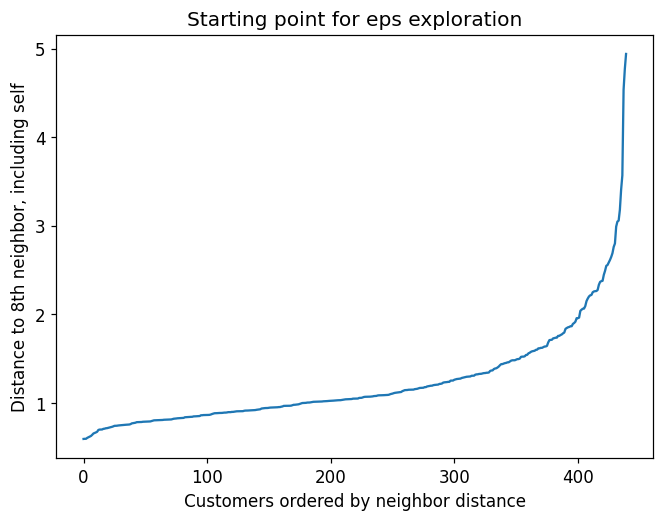

,eps,Clusters,Noise count,Assigned fraction,Silhouette on assigned
0,0.6,1,427,0.030,NaN
1,0.8,2,293,0.334,0.507
2,1.0,2,146,0.668,0.245
3,1.2,1,85,0.807,NaN
4,1.4,1,58,0.868,NaN
5,1.6,1,39,0.911,NaN


In [7]:
from sklearn.neighbors import NearestNeighbors
min_samples = 8
neighbor_distances = NearestNeighbors(n_neighbors=min_samples).fit(Z).kneighbors(Z)[0]
plt.plot(np.sort(neighbor_distances[:,-1]))
plt.xlabel('Customers ordered by neighbor distance'); plt.ylabel('Distance to 8th neighbor, including self')
plt.title('Starting point for eps exploration'); plt.show()
rows = []
for radius in [.6,.8,1.0,1.2,1.4,1.6]:
    labels = DBSCAN(eps=radius,min_samples=min_samples).fit_predict(Z)
    assigned = labels >= 0
    clusters = len(set(labels[assigned]))
    silhouette = np.nan
    if 1 < clusters < assigned.sum():
        silhouette = silhouette_score(Z[assigned],labels[assigned])
    rows.append([radius,clusters,(~assigned).sum(),assigned.mean(),silhouette])
display(pd.DataFrame(rows,columns=['eps','Clusters','Noise count','Assigned fraction','Silhouette on assigned']).round(3))
eps = 1.0  # Demonstration setting. Assess the table before treating it as a segmentation.
dbscan_labels = DBSCAN(eps=eps,min_samples=min_samples).fit_predict(Z)


## 6. Compare the same customers in one common map
PCA provides two plotting coordinates. Every clustering model above was fitted in all six transformed and standardized dimensions. Overlap or apparent gaps in this projection may differ from the full space.

Colors represent arbitrary group IDs independently within each method. Gray crosses identify DBSCAN noise.

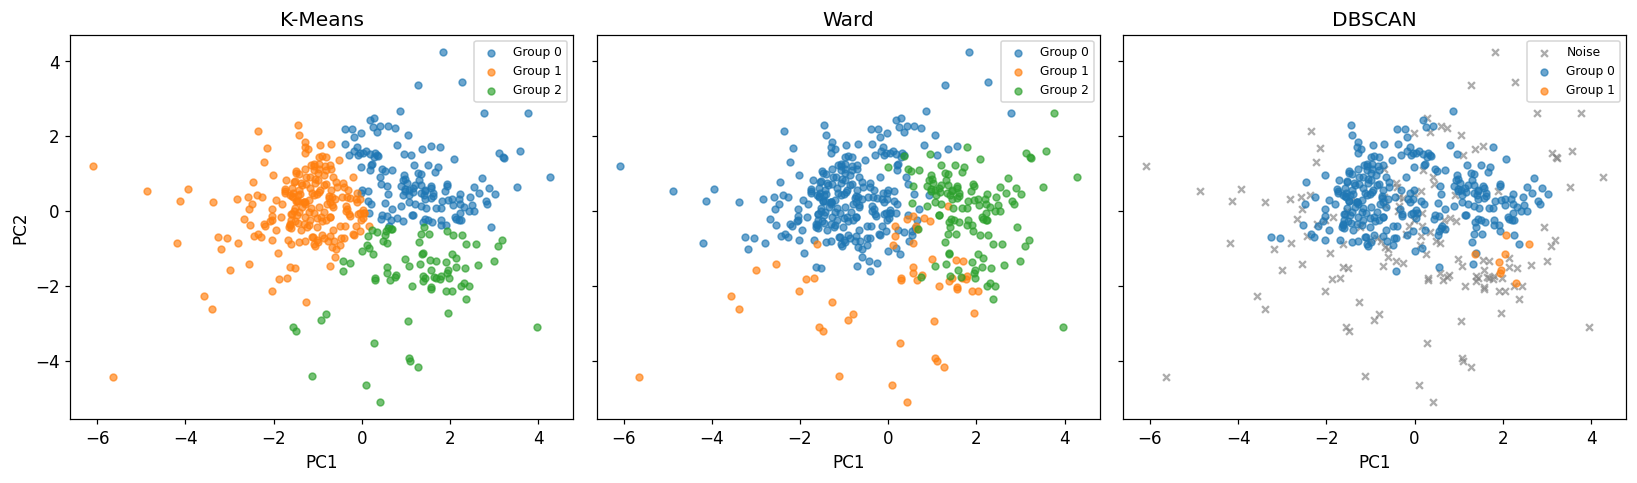

The map retains 71.3% of standardized log-spending variance.


In [8]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
map_coordinates = pca.fit_transform(Z)
print(f'The map retains {pca.explained_variance_ratio_.sum():.1%} of standardized log-spending variance.')
results = {'K-Means':kmeans_labels,'Ward':ward_labels,'DBSCAN':dbscan_labels}
fig,axes=plt.subplots(1,3,figsize=(15,4.5),sharex=True,sharey=True)
for (method,labels),ax in zip(results.items(),axes):
    for group in np.unique(labels):
        selected = labels==group
        ax.scatter(*map_coordinates[selected].T,s=20,alpha=.65,
                   color='gray' if group==-1 else plt.cm.tab10(int(group)%10),
                   marker='x' if group==-1 else 'o',label='Noise' if group==-1 else f'Group {group}')
    ax.set(title=method,xlabel='PC1'); ax.legend(fontsize=8)
axes[0].set_ylabel('PC2'); plt.tight_layout(); plt.show()


## 7. Compare coverage and separation
DBSCAN silhouette excludes noise here. Its score is calculated on a different subset from the other methods, so use coverage alongside the score. A single remaining group has an undefined silhouette. Noise points are left unassigned under the chosen density criterion.

In [9]:
comparison=[]
for method,labels in results.items():
    assigned = labels>=0
    groups = np.unique(labels[assigned])
    score = np.nan
    if 1 < len(groups) < assigned.sum():
        score = silhouette_score(Z[assigned],labels[assigned])
    comparison.append([method,len(groups),int((~assigned).sum()),assigned.mean(),score])
display(pd.DataFrame(comparison,columns=['Method','Groups','Noise','Coverage','Silhouette on assigned']).round(3))


,Method,Groups,Noise,Coverage,Silhouette on assigned
0,K-Means,3,0,1.000,0.258
1,Ward,3,0,1.000,0.255
2,DBSCAN,2,146,0.668,0.245


## 8. Name the segments from their actual purchases
Inspect median annual spending and group sizes. The heatmaps show average standardized log-spending, so zero is the dataset average in that transformed representation. The tables retain monetary units.

Write a descriptive name for each segment and one concrete offer the distributor could test. Describe DBSCAN noise separately because these customers may have very different profiles from each other.

,Customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Group,,,,,,,
0,145,12205.0,7209.0,9965.0,2033.0,3378.0,2005.0
1,212,9635.0,1598.5,2151.0,2151.0,274.5,686.0
2,83,1531.0,6154.0,10487.0,398.0,4196.0,490.0


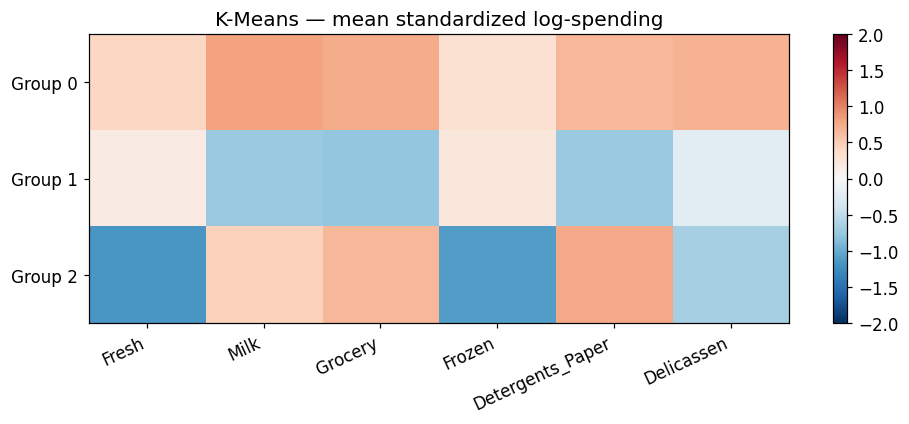

,Customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Group,,,,,,,
0,262,11113.0,2028.0,2583.5,2382.0,358.5,864.0
1,53,1689.0,4230.0,7854.0,661.0,2970.0,156.0
2,125,5981.0,8259.0,12469.0,1148.0,5618.0,1682.0


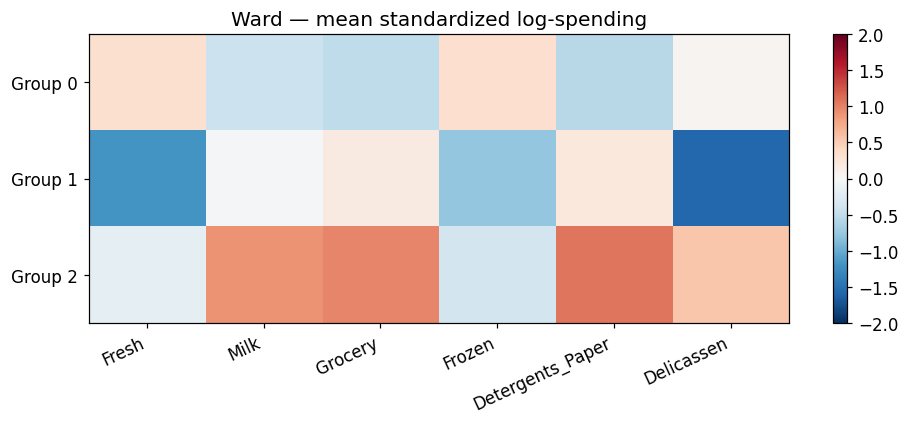

,Customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Group,,,,,,,
-1,146,4438.0,4745.0,6101.5,954.5,833.0,506.0
0,286,9771.5,3199.0,3840.0,1786.5,763.5,1053.0
1,8,1492.5,8606.5,11997.5,182.0,5244.0,1764.0


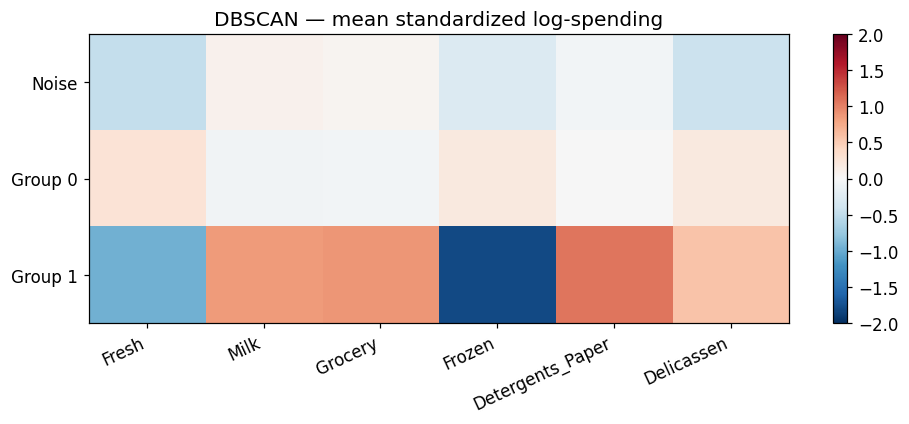

K-Means
Ward
DBSCAN


In [10]:
for method,labels in results.items():
    print(method)
    profiles = X.assign(Group=labels).groupby('Group').median()
    profiles.insert(0,'Customers',pd.Series(labels).value_counts().sort_index())
    display(profiles.round(1))
    standardized_profiles = pd.DataFrame(Z,columns=features).assign(Group=labels).groupby('Group').mean()
    fig,ax=plt.subplots(figsize=(9,4))
    im=ax.imshow(standardized_profiles,vmin=-2,vmax=2,cmap='RdBu_r',aspect='auto')
    ax.set_xticks(range(6),features,rotation=25,ha='right')
    ax.set_yticks(range(len(standardized_profiles)),[f'Group {g}' if g>=0 else 'Noise' for g in standardized_profiles.index])
    ax.set_title(method+' — mean standardized log-spending')
    fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()


## 9. Reveal business channel
Channel 1 denotes Horeca (hotel/restaurant/café), and channel 2 retail. Inspect channel proportions inside each discovered group. Channel was excluded from fitting and parameter exploration. It is one external descriptor of customers, and the spending-based segmentation may have a different level of detail.

In [11]:
for method,labels in results.items():
    print(method)
    display(pd.crosstab(pd.Series(labels,name='Group'),data['Channel'].map({1:'Horeca',2:'Retail'}),
                        normalize='index').round(3))


Channel,Horeca,Retail
Group,,
0,0.386,0.614
1,0.986,0.014
2,0.398,0.602


Channel,Horeca,Retail
Group,,
0,0.958,0.042
1,0.509,0.491
2,0.160,0.840


Channel,Horeca,Retail
Group,,
-1,0.692,0.308
0,0.689,0.311
1,0.000,1.000


K-Means
Ward
DBSCAN


## 10. Final discussion and short assignment
1. Choose one method and justify your parameters using group sizes, separation, coverage and purchasing profiles.
2. Name two segments from observed median spending and propose one testable action for each.
3. Explain what changed when varying `k` or `eps`.
4. Explain why a two-dimensional plot can hide relationships used by the clustering model.
5. Explain how you would handle a newly arriving customer. K-Means offers `predict` with the fitted preprocessing. Hierarchical clustering and DBSCAN require an explicitly chosen assignment or refitting strategy.

<details><summary>Instructor notes for preparation</summary>
Use the three small notebooks to teach mechanics before this case. Let students question k=3 and eps=1.0, which are transparent demonstration settings. DBSCAN can yield one main group and substantial noise on this dataset. That outcome helps discuss whether density-based segmentation meets the business objective. Avoid selecting parameters merely to make every method yield the same group count. A segment description must be supported by the displayed spending profiles. No ground-truth customer segmentation is provided.
</details>

[Algorithm reference](https://scikit-learn.org/stable/modules/clustering.html) · [Dataset and CC BY 4.0 attribution](https://archive.ics.uci.edu/dataset/292/wholesale+customers).